# A–B–A similarity map (docs/34, Phase 1) — EXPLORATORY

**Question.** How do forgetting and transfer depend on label and input similarity?

**Slot.** `docs/24` §4 core, controlled paradigm (A–B–A), exploratory extension (`docs/34`). The stream
is parked until this map is reported (`docs/34` §8).

**Design (Phase 1, amended 2026-11-10).** Learner, data, training and measurement exactly as docs/28 §2
(1M, N = 300, μP, matched-loss stopping). γ₀ ∈ {0.1, 1, 10}; seeds 16–23 (fresh). Two slices:
- the H sweep, H ∈ {0, 2, 4, 6, 8, 12, 16}, at s_f ∈ {1, 0.9};
- the s_f sweep, s_f ∈ {1, 0.95, 0.9, 0.8, 0.6, 0.4, 0.2, 0.1}, at H ∈ {0, 4, 8}.

That is 32 configurations × 3 γ₀ × 8 seeds = 768 arms, plus one fresh-noise identity arm per γ₀.


## 2. Pre-commit: expectations (docs/34 §6, quoted verbatim; written and committed before submission)

Source: [`docs/34-aba-similarity-map.md`](../../docs/34-aba-similarity-map.md), ratified by Kati
2026-11-10, with the dated amendments of the same day (before any map arm). EXPLORATORY: no
confirmatory claims; nothing enters a Bonferroni family. These are directions, not thresholds:

- **E1 (Hiratani corners).** Forgetting (f and bottleneck) is largest at high input similarity × H8,
  and smallest at low input similarity, at every γ₀.
- **E2 (shape in s_f).** At H4 and H8, f is monotonic in s_f, *or* peaked at intermediate s_f. Record
  which. A peak would match Lee et al. and Hiratani.
- **E3 (shape in H).** At s_f ∈ {1, 0.9}, f rises from H0 to H8 (a dose). Behaviour at H12 and H16
  falls below chance on A while geometry recovers towards H0.
- **E4 (H16).** At γ₀ 0.1, A's capacity is unchanged at H16 (readout flip only). At γ₀ 10, record
  whether capacity is lost (feature rebuilding).
- **E5 (Menghi tension).** At intermediate s_f (0.4–0.6) with H0, forward transfer stays positive. If
  it turns negative, that matches Menghi's partly-similar-input interference.
- **E6 (richness).** The ordering across similarity cells is the same at every γ₀; only size and
  channel change.
- **E7 (restoration; amended 2026-11-10).** Restoration is complete at high input similarity and falls
  below 0.9 as input similarity drops, at γ₀ ≥ 1 (cf. docs/33 limits: ρ = 0.862 at h 8 jump, γ₀ 10).


### Reading rules (fixed before the run)

Reading rules (operationalised by Claude on 2026-11-10, before any map arm; 95% t-intervals over the
8 seeds, description only, no family). Each expectation is read as held / not held / unresolved.
- E1: at each γ0, among the H4/H8 cells of the s_f sweep, the cell with the largest mean f AND the
  largest mean bottleneck forgetting is H8 × s_f ∈ {1, 0.95, 0.9}, and the cell with the smallest mean f
  has s_f ≤ 0.2. Held if both at every γ0. Not held if, at any γ0, another cell's interval lies wholly
  above the best H8 × high-similarity cell's interval, or the smallest-f cell has s_f > 0.2 and its
  interval lies wholly below every s_f ≤ 0.2 cell's interval. Otherwise unresolved.
- E2: per γ0 and H ∈ {4, 8}, across s_f: "peaked" if some interior s_f (0.2–0.95) has an interval
  wholly above both endpoint intervals (s_f 0.1 and 1); "monotone" if no peak and the Spearman
  correlation of the means with s_f is ≥ 0.8; "decreasing" if ≤ −0.8; otherwise unresolved. Recorded
  per (γ0, H). Held if every (γ0, H) is monotone or peaked; not held if any is decreasing.
- E3: at s_f ∈ {1, 0.9}: (i) f(H8) − f(H0), paired, has its interval above 0 and the means rise
  over H 0, 2, 4, 6, 8 with at most one inversion; (ii) the network's accuracy on A at the end of B
  has its interval below 0.5 at H12 and H16; (iii) Δlog α_A at H16 minus at H8, paired, has its
  interval above 0. Held if (i)–(iii) at both s_f and every γ0. Not held if any part has its interval
  wholly on the wrong side. Otherwise unresolved.
- E4: γ0 0.1, H16 × s_f 1: Δlog α_A(A → B). Held if the interval lies within ±0.05 (the docs/29
  SESOI for log α); not held if it excludes 0; otherwise unresolved. At γ0 10 it is recorded.
- E5: H0 × s_f ∈ {0.4, 0.6}: FT_beh. Held if its interval is above 0 at both s_f and every γ0; not
  held (matches Menghi) if it is below 0 at any; otherwise unresolved. FT_geo specific is reported.
- E6: Spearman correlation of the cell means of f across the 32 Phase 1 cells, for each γ0 pair.
  Held if every pair is ≥ 0.8; not held if any is < 0.5; otherwise unresolved.
- E7: γ0 1 and 10, H4 and H8 s_f slices: held if mean ρ ≥ 0.9 at every s_f ∈ {1, 0.95, 0.9} and the
  interval of ρ is below 0.9 at s_f 0.1 or 0.2; not held if the interval lies wholly below 0.9 at
  some s_f ≥ 0.9, or wholly at or above 0.9 at both s_f 0.1 and 0.2; otherwise unresolved. Per
  (γ0, H), then all four combined.


## 3. Setup

In [1]:
import os, sys, json, math
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[_v] = "1"
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import numpy as np
import matplotlib.pyplot as plt
import aba_lib as L
import aba_map_analysis as A
plt.rcParams.update({"figure.dpi": 80, "font.family": "DejaVu Sans", "figure.facecolor": "#fcfcfb",
                     "axes.facecolor": "#fcfcfb", "axes.spines.top": False, "axes.spines.right": False})
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
LEVEL_COL = ["#2a78d6", "#eb6834", "#1baf7a"]      # validated categorical slots 1-3 (slice levels)
GCOL = {0.1: "#2a78d6", 1.0: "#eb6834", 10.0: "#1baf7a"}

cfg = A.map_cfg()
MAP_JSONL = L.REPO / "results" / "aba" / "FULL_e3011fa49aca1994.jsonl"   # job 4651 (pinned 2026-11-11, docs/36)
HAVE = MAP_JSONL.exists()
SEEDS = list(cfg.seeds)
print(f"lib hash {L.lib_hash()}; stamp now {L.git_stamp()}")
print(f"checkpoint {MAP_JSONL.name}: {'present' if HAVE else 'NOT YET RUN'}")
print(json.dumps({k: v for k, v in cfg.key_fields().items()}, indent=None)[:600])
print(f"γ0 {cfg.gammas}; H {cfg.hammings}; s_f {cfg.s_fs}; seeds {SEEDS[0]}–{SEEDS[-1]} (n = {len(SEEDS)}); "
      f"sampling unit: one (arrangement, init) draw per seed, paired across cells and γ0")
print(f"Phase 1 arms: {len(L.phase1_specs(cfg))} ({len(A.phase1_cells(cfg))} configurations)")


lib hash e46dde42457277c4; stamp now {'commit': 'afb637621c87', 'dirty': True}
checkpoint FULL_e3011fa49aca1994.jsonl: present
{"P": 16, "d": 150, "D": 4, "R": 1.0, "M": 150, "N": 300, "lr0": 5.0, "n_base": 64, "target_loss": 0.05, "max_steps": 20000, "record_every": 25, "n_t": 200, "center_policy": "all", "ntk_per_manifold": 20, "probe_hamming": 4, "n_probe_neutral": 4, "refit_steps": 2000, "bottleneck_n": 16, "probe_hammings": [0, 2, 4, 6, 8, 12, 16]}
γ0 (0.1, 1.0, 10.0); H (0, 2, 4, 6, 8, 12, 16); s_f (1.0, 0.95, 0.9, 0.8, 0.6, 0.4, 0.2, 0.1); seeds 16–23 (n = 8); sampling unit: one (arrangement, init) draw per seed, paired across cells and γ0
Phase 1 arms: 771 (32 configurations)


## 4. Load and validate (must pass)

In [2]:
if HAVE:
    D, F, ROWS = A.load_map(MAP_JSONL, cfg)
    CHECKS = A.validate(D, F, ROWS, SEEDS, cfg)
    for name, ok, det in CHECKS:
        print(f"{'PASS' if ok else 'FAIL'}  {name}  {det}")
    assert all(ok for _, ok, _ in CHECKS), "validation failed: no readings"
    T = A.table(D, SEEDS, cfg)


PASS  all Phase 1 arms present  771/771
PASS  every arm usable (every phase converged)  771 usable
PASS  schema: every field present and finite  0 arms with gaps
PASS  one commit, clean tree  {"commit": "07b304786dc1", "dirty": false}
PASS  one lib hash  e3011fa49aca1994
PASS  realised s_r = 1 − H/8 exactly  
PASS  ρ_in = 1 at s_f 1 (exact copy)  168 arms
PASS  task-vector cos on h₀ identical across γ0 (I6)  
PASS  identity cell (H0, s_f 1, copy): 0 updates on B, Δlog α_A = 0  24 arms
PASS  fresh-noise identity arm per γ0 present (Δlog α_A reported)  γ0 0.1: +0.0000, γ0 1: +0.0000, γ0 10: +0.0000


## 5. Results (EXPLORATORY)

Mean and 95% t-interval over 8 seeds, per configuration; signed values only; nothing pooled across
configurations. Under matched-loss stopping a similar B needs fewer updates, so similarity effects include their effect on exposure (steps on B are plotted beside every map). EXPLORATORY.

**Profiles over the nominal axes.** One figure per quantity. Columns are γ₀. Row 1: the H sweep (lines
s_f 1, 0.9); row 2: updates on B for the same cells; row 3: the s_f sweep (lines H 0, 4, 8); row 4:
updates on B for the same cells. (With two slices, profiles are the map; a 2-D heatmap needs Phase 2.)


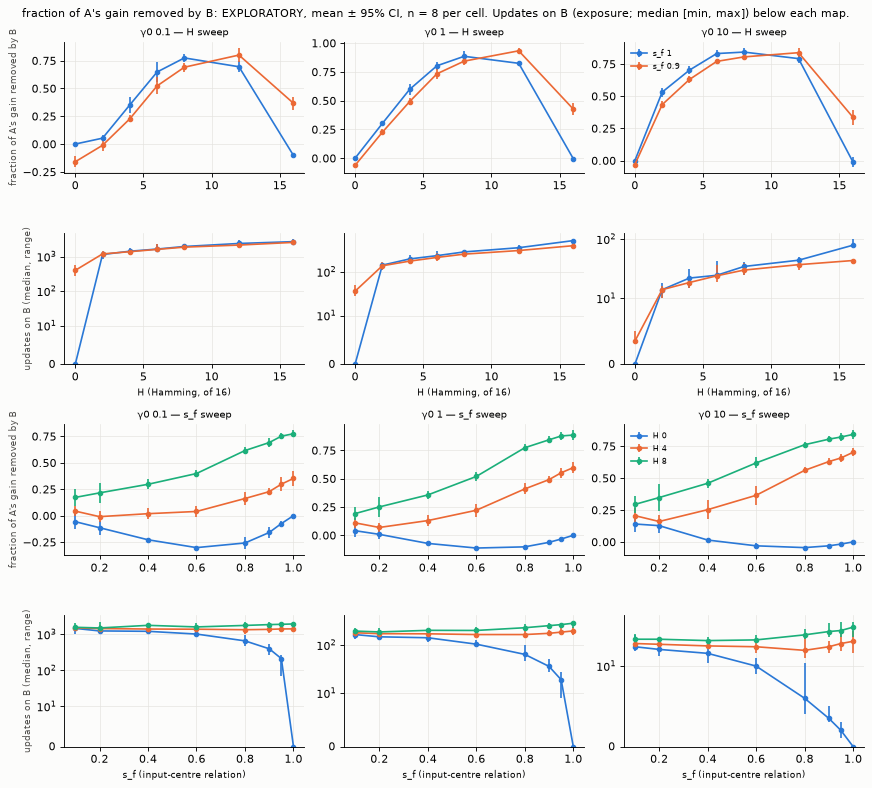

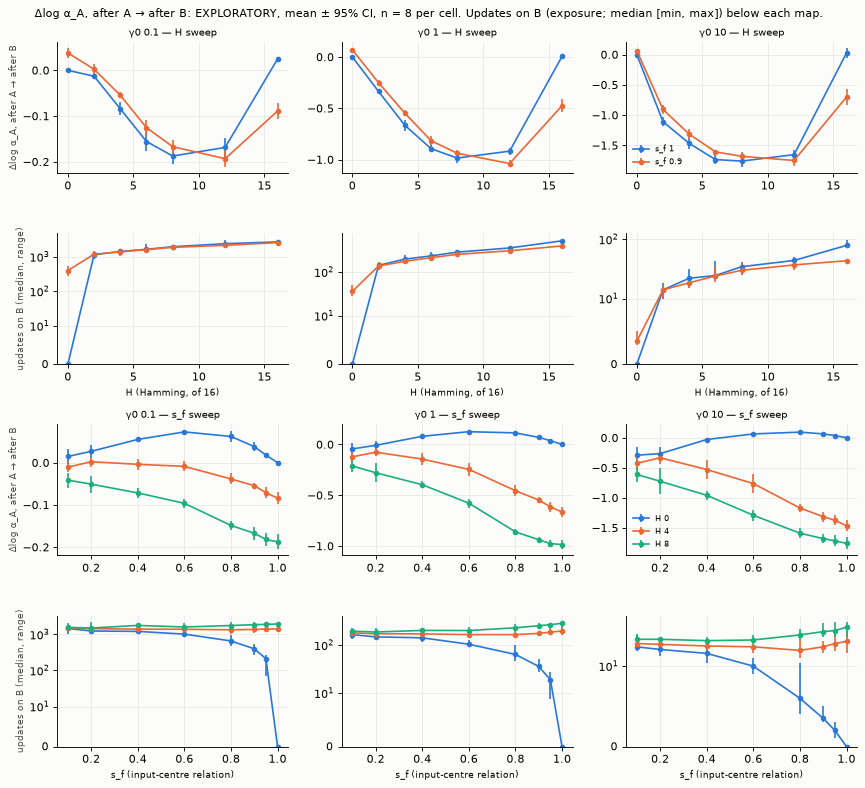

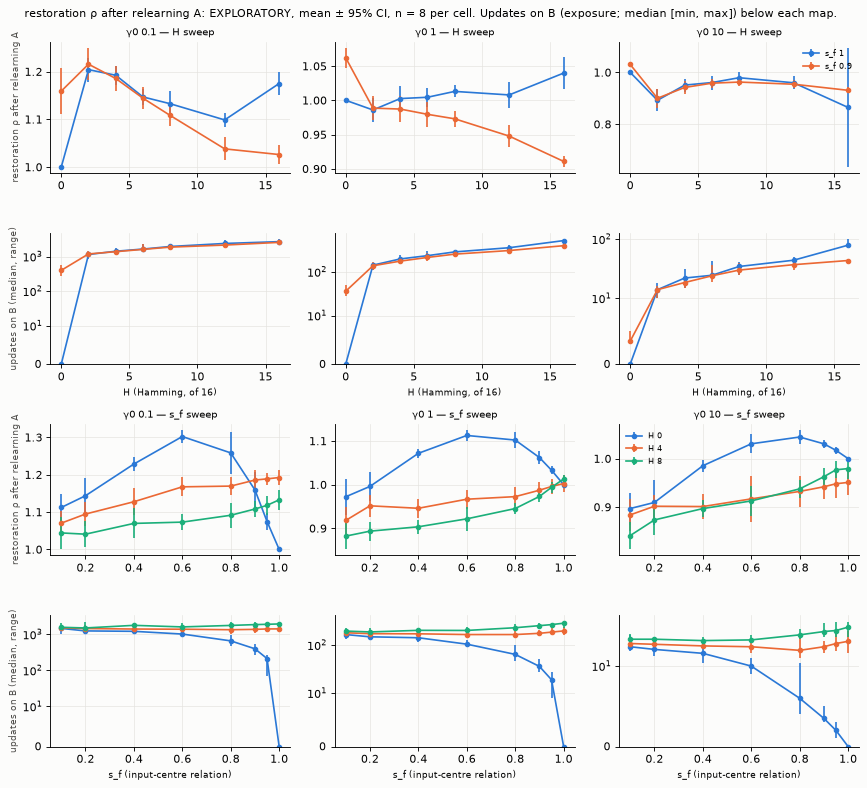

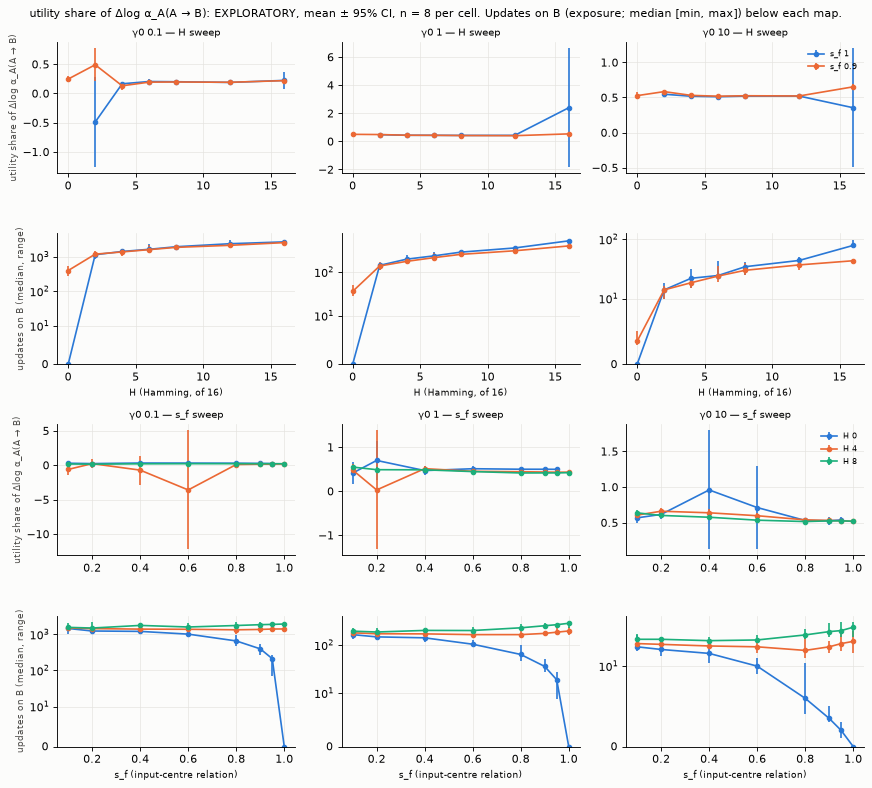

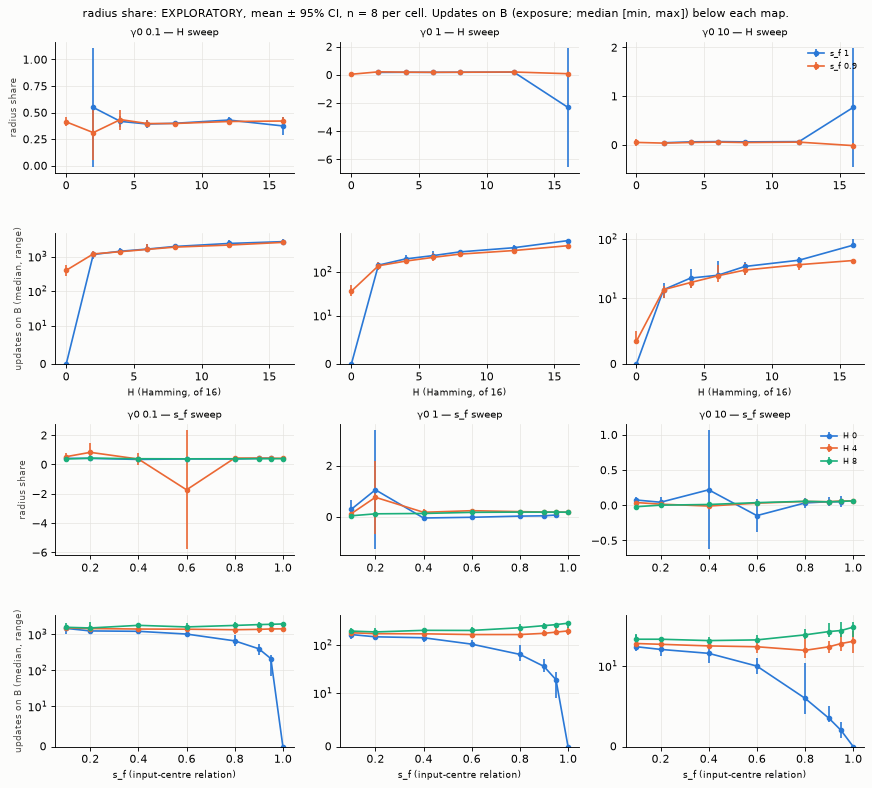

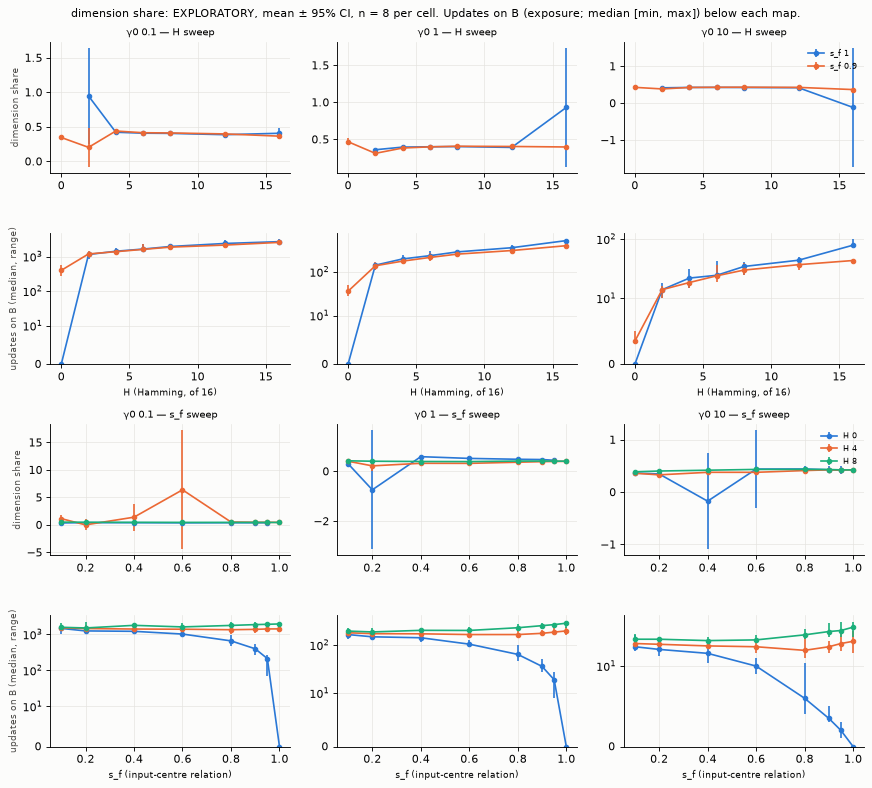

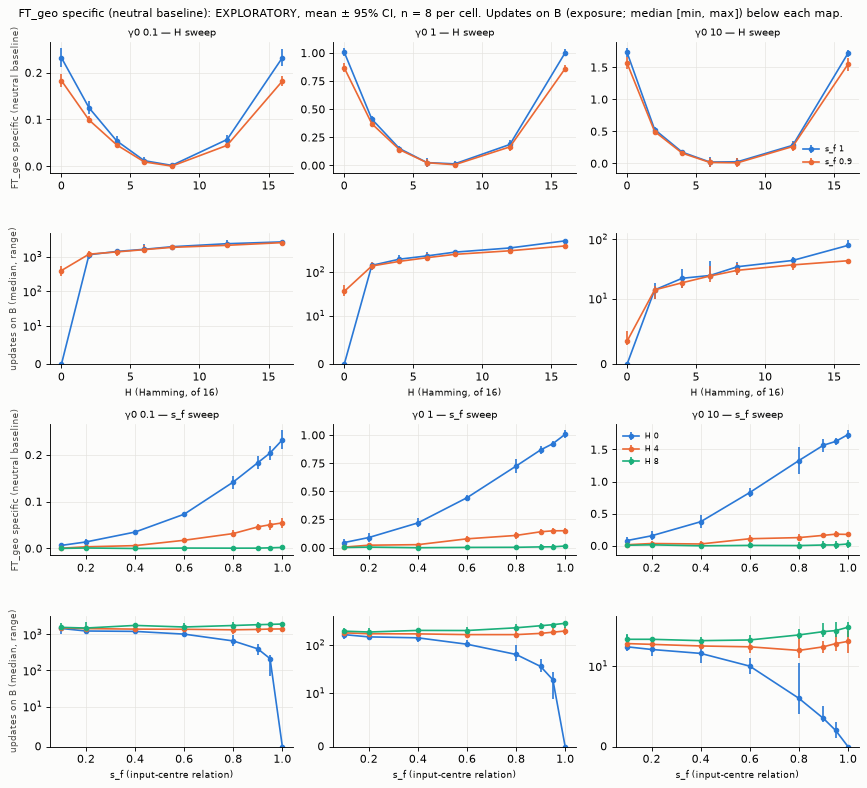

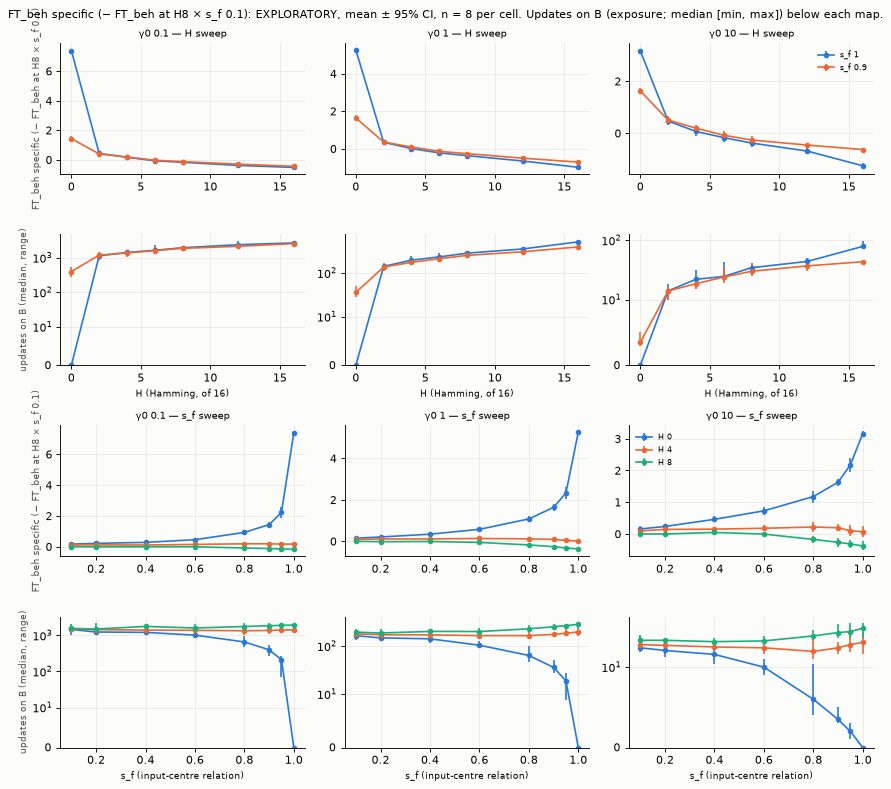

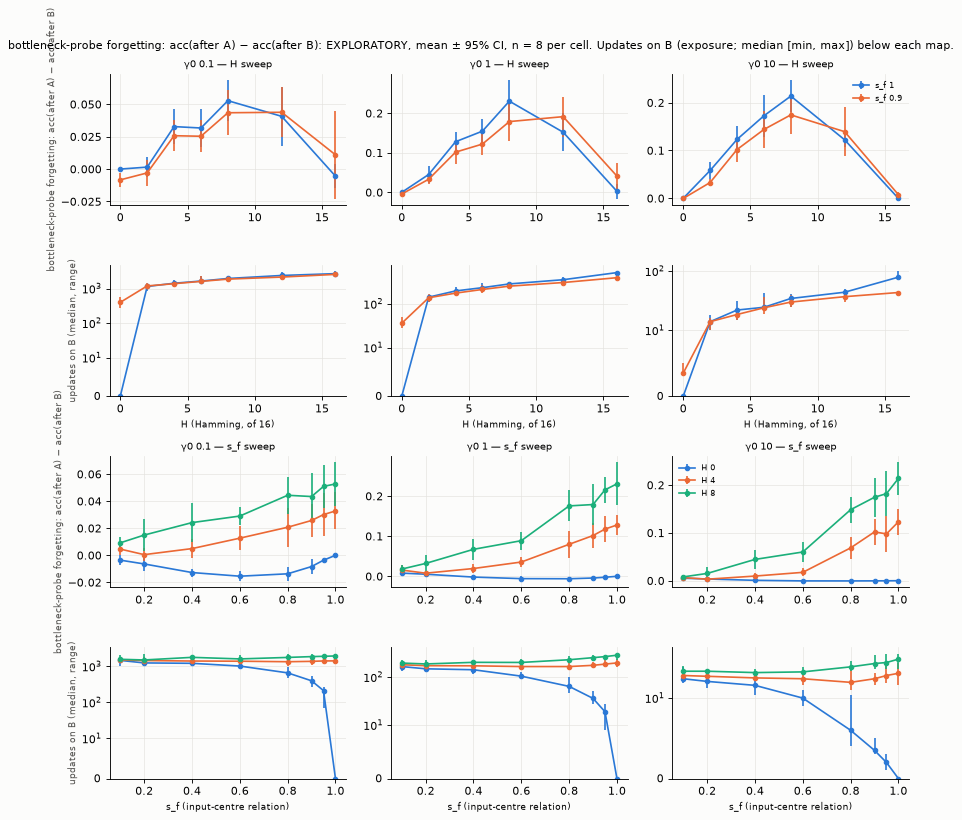

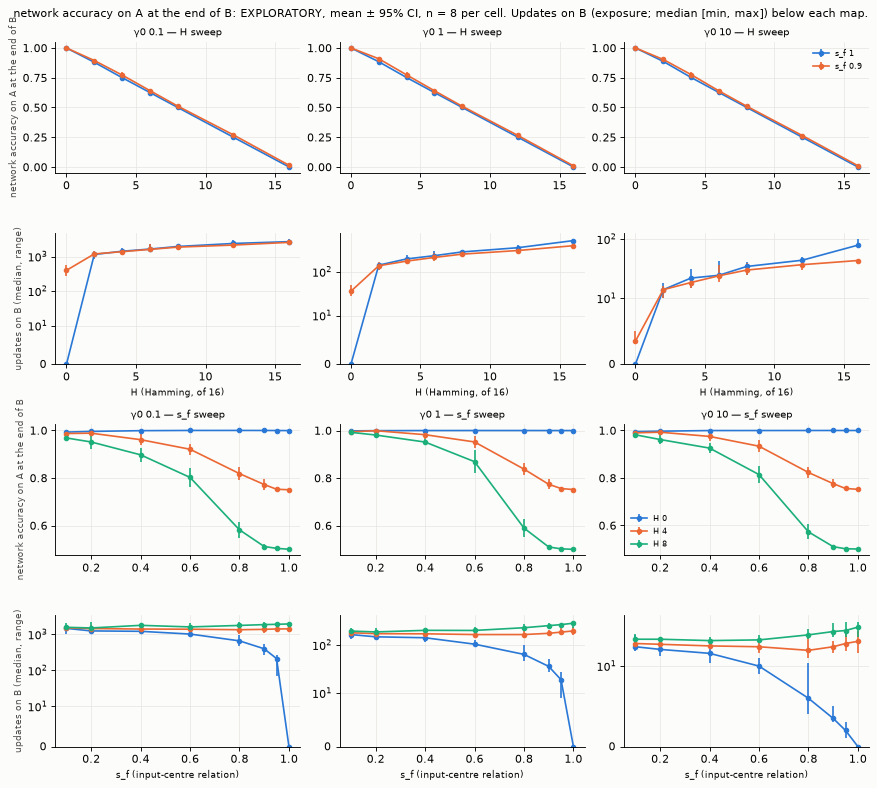

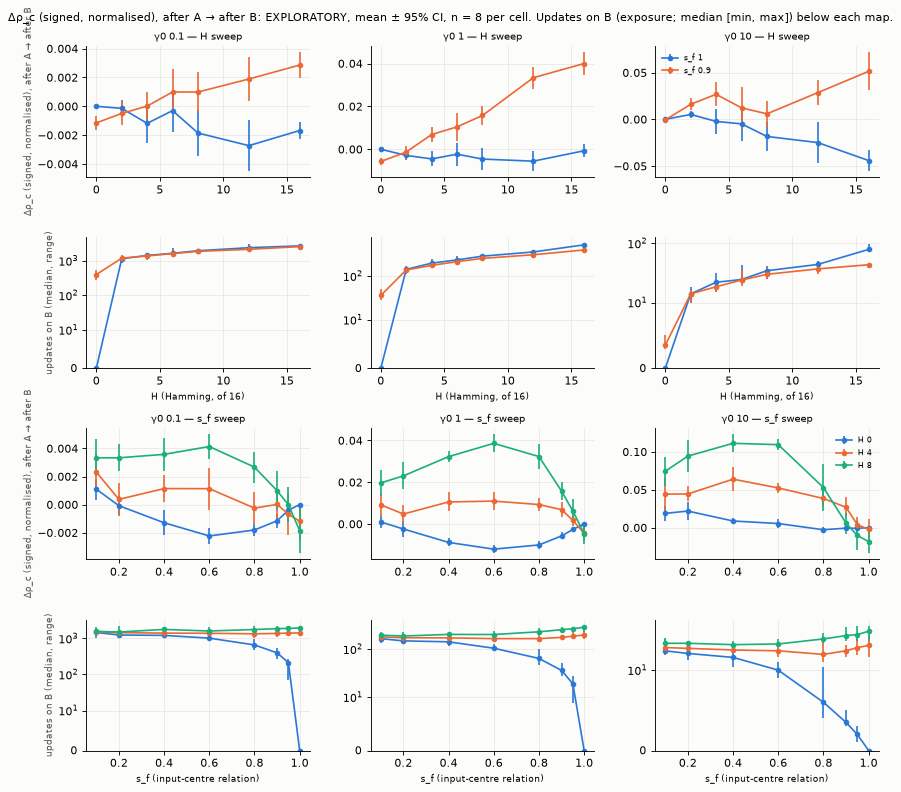

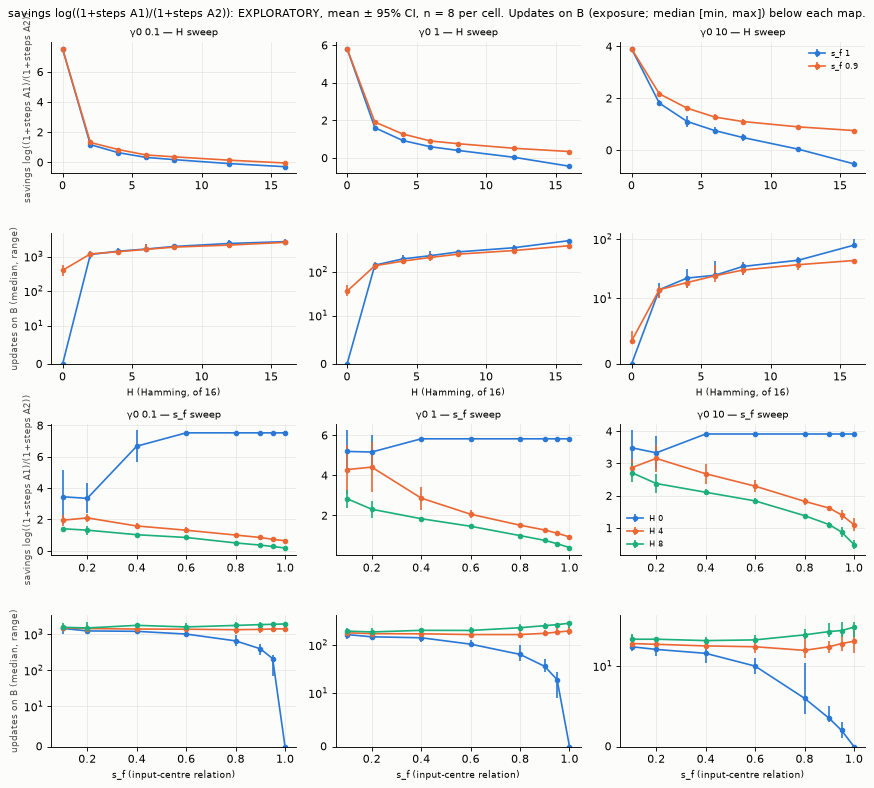

In [3]:
def profile(q):
    lab = A.QUANTS[q][0]
    fig, axes = plt.subplots(4, 3, figsize=(11, 10), sharex="row")
    for j, g in enumerate(A.GAMMAS):
        for row, (xs, lines, key) in enumerate([(cfg.hammings, A.H_SWEEP_SF, lambda x, l: (x, l)),
                                                (cfg.s_fs, A.SF_SWEEP_H, lambda x, l: (l, x))]):
            for k, qq in enumerate((q, "stepsB")):
                ax = axes[2 * row + k, j]
                for c, lev in enumerate(lines):
                    m = [T[qq, g, *key(x, lev)] if qq != "stepsB" else A.steps_range(D, g, *key(x, lev), SEEDS)
                         for x in xs]
                    ax.errorbar(xs, [v[0] for v in m], yerr=[[v[0] - v[1] for v in m], [v[2] - v[0] for v in m]],
                                color=LEVEL_COL[c], lw=1.5, marker="o", ms=4, capsize=0,
                                label=(f"s_f {lev:g}" if row == 0 else f"H {lev}"))
                if qq == "stepsB":
                    ax.set_yscale("symlog", linthresh=10)
                    ax.set_ylim(bottom=0)
                ax.grid(color=GRID, lw=0.6)
                if j == 0:
                    ax.set_ylabel(lab if qq == q else "updates on B (median, range)", fontsize=8, color=INK2)
                if 2 * row + k in (0, 2):
                    ax.set_title(f"γ0 {g:g}" + (" — H sweep" if row == 0 else " — s_f sweep"), fontsize=9)
                if k == 1:
                    ax.set_xlabel("H (Hamming, of 16)" if row == 0 else "s_f (input-centre relation)", fontsize=8)
                if j == 2 and k == 0:
                    ax.legend(frameon=False, fontsize=7)
    fig.suptitle(f"{lab}: EXPLORATORY, mean ± 95% CI, n = 8 per cell. Updates on B (exposure; median [min, max]) "
                 "below each map.",
                 fontsize=10)
    fig.tight_layout()
    plt.show()

if HAVE:
    for q in ("f", "dA", "rho", "u", "r", "d", "ftgeo", "ftbeh_spec", "bott", "accA", "drhoc", "savings"):
        profile(q)


**Against measured similarity (docs/34 §4).** One point per configuration and γ₀: x is the mean
measured similarity over seeds, y the mean ± 95% CI of the quantity. Circles: on the H sweep; squares: s_f
sweep only. Updates on B as median [min, max]. FT_beh specific is relative to H8 × s_f 0.1 of the same seed and γ₀. Under matched-loss stopping a similar B needs fewer updates, so similarity effects include their effect on exposure (steps on B are plotted beside every map). EXPLORATORY.


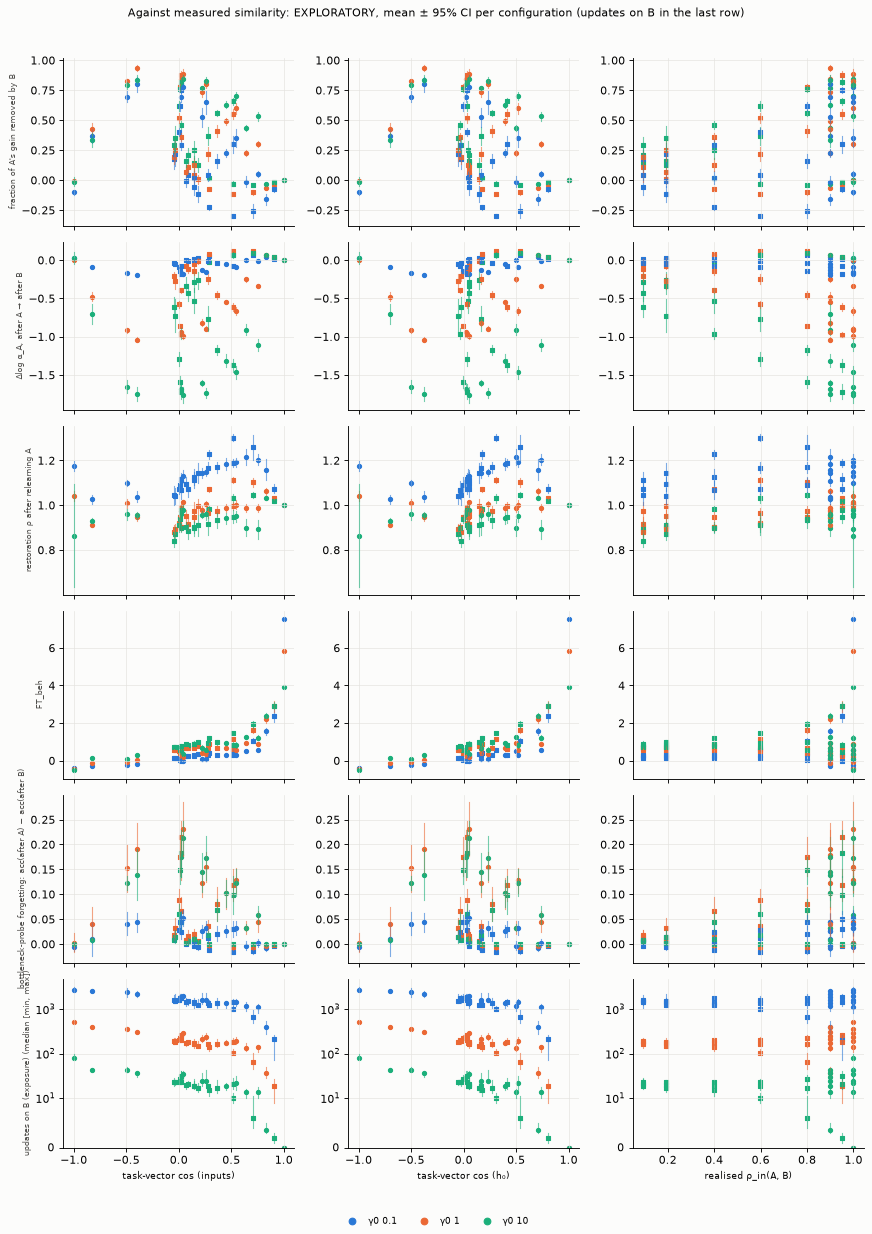

In [4]:
def measured(qs=("f", "dA", "rho", "ftbeh", "bott", "stepsB")):
    fig, axes = plt.subplots(len(qs), 3, figsize=(11, 2.6 * len(qs)), sharex="col")
    for i, q in enumerate(qs):
        for j, (mk, mlab) in enumerate(A.MEASURED.items()):
            ax = axes[i, j]
            for (h, sf) in A.phase1_cells(cfg):
                for g in A.GAMMAS:
                    x = np.mean([D[s, g, h, sf]["relations"][mk] for s in SEEDS])
                    m, lo, hi = T[q, g, h, sf] if q != "stepsB" else A.steps_range(D, g, h, sf, SEEDS)
                    marker = "o" if sf in A.H_SWEEP_SF else "s"     # circle: on the H sweep; square: s_f sweep only
                    ax.plot([x, x], [lo, hi], color=GCOL[g], lw=1, alpha=0.6)
                    ax.scatter([x], [m], color=GCOL[g], s=14, marker=marker)
            if q == "stepsB":
                ax.set_yscale("symlog", linthresh=10)
                ax.set_ylim(bottom=0)
            ax.grid(color=GRID, lw=0.6)
            if j == 0:
                ax.set_ylabel(A.QUANTS[q][0] + (" (median [min, max])" if q == "stepsB" else ""), fontsize=7, color=INK2)
            if i == len(qs) - 1:
                ax.set_xlabel(mlab, fontsize=8)
    from matplotlib.lines import Line2D
    fig.legend(handles=[Line2D([], [], marker="o", ls="", color=GCOL[g], label=f"γ0 {g:g}") for g in A.GAMMAS],
               loc="lower center", ncol=3, frameon=False, fontsize=8)
    fig.suptitle("Against measured similarity: EXPLORATORY, mean ± 95% CI per configuration (updates on B in the last row)",
                 fontsize=10)
    fig.tight_layout(rect=(0, 0.03, 1, 0.97))
    plt.show()

if HAVE:
    measured()


**Third independent sample of the docs/28 configurations (amendment b).** h 4 and h 8 × s_f {1, 0.9,
0.1}, seeds 16–23, beside seeds 8–15 (job 4396) and seeds 0–7 (job 4349). Unpooled; 95% intervals here
(the docs/28 readings used 99.17%). Not a reading of any docs/28 hypothesis. EXPLORATORY.


In [5]:
import aba_summary as S
if HAVE:
    PRIOR = S.load()
    hdr = "| H | s_f | γ0 | quantity | seeds 16–23 (map) | seeds 8–15 | seeds 0–7 |"
    lines = [hdr, "|---|---|---|---|---|---|---|"]
    fn = {"f": S.frac_removed, "dA": lambda r: r["backward"]["A1_to_B"]["total"], "rho": S.restoration,
          "ftbeh": lambda r: r["behaviour"]["FT_beh"]}
    for h in (4, 8):
        for sf in (1.0, 0.9, 0.1):
            for g in A.GAMMAS:
                for q in ("f", "dA", "rho", "ftbeh"):
                    cells = [A._f(T[q, g, h, sf])]
                    for run in ("seeds 8–15", "seeds 0–7"):
                        P = PRIOR[run]
                        cells.append(A._f(A.ci([fn[q](P[s, g, h, sf]) for s in S.seeds_of(run)])))
                    lines.append(f"| {h} | {sf:g} | {g:g} | {q} | " + " | ".join(cells) + " |")
    from IPython.display import Markdown, display
    display(Markdown("\n".join(lines)))


| H | s_f | γ0 | quantity | seeds 16–23 (map) | seeds 8–15 | seeds 0–7 |
|---|---|---|---|---|---|---|
| 4 | 1 | 0.1 | f | +0.352 [+0.279, +0.425] | +0.387 [+0.314, +0.460] | +0.393 [+0.323, +0.463] |
| 4 | 1 | 0.1 | dA | -0.084 [-0.098, -0.070] | -0.097 [-0.111, -0.083] | -0.089 [-0.105, -0.072] |
| 4 | 1 | 0.1 | rho | +1.192 [+1.173, +1.212] | +1.173 [+1.149, +1.196] | +1.198 [+1.166, +1.229] |
| 4 | 1 | 0.1 | ftbeh | +0.299 [+0.217, +0.381] | +0.269 [+0.186, +0.351] | +0.259 [+0.210, +0.307] |
| 4 | 1 | 1 | f | +0.598 [+0.550, +0.646] | +0.615 [+0.576, +0.654] | +0.620 [+0.569, +0.672] |
| 4 | 1 | 1 | dA | -0.665 [-0.719, -0.612] | -0.685 [-0.723, -0.647] | -0.673 [-0.734, -0.613] |
| 4 | 1 | 1 | rho | +1.002 [+0.984, +1.021] | +1.017 [+1.000, +1.034] | +1.005 [+0.990, +1.021] |
| 4 | 1 | 1 | ftbeh | +0.568 [+0.493, +0.643] | +0.556 [+0.481, +0.632] | +0.515 [+0.440, +0.589] |
| 4 | 1 | 10 | f | +0.702 [+0.671, +0.733] | +0.719 [+0.692, +0.747] | +0.670 [+0.598, +0.742] |
| 4 | 1 | 10 | dA | -1.468 [-1.558, -1.377] | -1.481 [-1.542, -1.419] | -1.384 [-1.551, -1.217] |
| 4 | 1 | 10 | rho | +0.951 [+0.925, +0.976] | +0.978 [+0.943, +1.014] | +0.963 [+0.946, +0.980] |
| 4 | 1 | 10 | ftbeh | +0.819 [+0.653, +0.985] | +0.832 [+0.679, +0.985] | +0.708 [+0.526, +0.891] |
| 4 | 0.9 | 0.1 | f | +0.227 [+0.195, +0.258] | +0.264 [+0.206, +0.321] | +0.281 [+0.234, +0.328] |
| 4 | 0.9 | 0.1 | dA | -0.055 [-0.061, -0.048] | -0.066 [-0.077, -0.055] | -0.063 [-0.075, -0.052] |
| 4 | 0.9 | 0.1 | rho | +1.186 [+1.159, +1.212] | +1.164 [+1.139, +1.189] | +1.197 [+1.171, +1.223] |
| 4 | 0.9 | 0.1 | ftbeh | +0.319 [+0.241, +0.397] | +0.284 [+0.205, +0.363] | +0.296 [+0.227, +0.364] |
| 4 | 0.9 | 1 | f | +0.492 [+0.463, +0.520] | +0.494 [+0.459, +0.530] | +0.523 [+0.488, +0.559] |
| 4 | 0.9 | 1 | dA | -0.547 [-0.580, -0.515] | -0.551 [-0.584, -0.517] | -0.568 [-0.611, -0.525] |
| 4 | 0.9 | 1 | rho | +0.987 [+0.969, +1.006] | +1.006 [+0.987, +1.024] | +0.991 [+0.976, +1.005] |
| 4 | 0.9 | 1 | ftbeh | +0.648 [+0.592, +0.705] | +0.618 [+0.536, +0.699] | +0.585 [+0.490, +0.680] |
| 4 | 0.9 | 10 | f | +0.629 [+0.600, +0.659] | +0.597 [+0.558, +0.636] | +0.594 [+0.544, +0.644] |
| 4 | 0.9 | 10 | dA | -1.316 [-1.399, -1.232] | -1.231 [-1.330, -1.131] | -1.226 [-1.343, -1.109] |
| 4 | 0.9 | 10 | rho | +0.942 [+0.917, +0.967] | +0.978 [+0.947, +1.010] | +0.963 [+0.944, +0.982] |
| 4 | 0.9 | 10 | ftbeh | +0.946 [+0.863, +1.029] | +0.887 [+0.740, +1.035] | +0.774 [+0.580, +0.969] |
| 4 | 0.1 | 0.1 | f | +0.043 [-0.002, +0.088] | +0.101 [+0.026, +0.175] | +0.071 [-0.004, +0.146] |
| 4 | 0.1 | 0.1 | dA | -0.011 [-0.022, +0.000] | -0.025 [-0.043, -0.007] | -0.016 [-0.033, +0.000] |
| 4 | 0.1 | 0.1 | rho | +1.070 [+1.038, +1.103] | +1.062 [+1.019, +1.105] | +1.080 [+1.035, +1.126] |
| 4 | 0.1 | 0.1 | ftbeh | +0.244 [+0.202, +0.286] | +0.149 [+0.106, +0.191] | +0.192 [+0.134, +0.250] |
| 4 | 0.1 | 1 | f | +0.110 [+0.068, +0.152] | +0.149 [+0.068, +0.229] | +0.127 [+0.074, +0.181] |
| 4 | 0.1 | 1 | dA | -0.122 [-0.168, -0.076] | -0.165 [-0.251, -0.079] | -0.139 [-0.197, -0.080] |
| 4 | 0.1 | 1 | rho | +0.918 [+0.887, +0.949] | +0.912 [+0.877, +0.947] | +0.915 [+0.886, +0.944] |
| 4 | 0.1 | 1 | ftbeh | +0.651 [+0.623, +0.679] | +0.587 [+0.524, +0.650] | +0.593 [+0.536, +0.651] |
| 4 | 0.1 | 10 | f | +0.206 [+0.147, +0.265] | +0.220 [+0.113, +0.327] | +0.220 [+0.151, +0.290] |
| 4 | 0.1 | 10 | dA | -0.427 [-0.540, -0.313] | -0.452 [-0.670, -0.235] | -0.453 [-0.595, -0.311] |
| 4 | 0.1 | 10 | rho | +0.884 [+0.851, +0.916] | +0.885 [+0.839, +0.932] | +0.881 [+0.853, +0.909] |
| 4 | 0.1 | 10 | ftbeh | +0.845 [+0.799, +0.891] | +0.780 [+0.695, +0.865] | +0.803 [+0.697, +0.910] |
| 8 | 1 | 0.1 | f | +0.774 [+0.741, +0.807] | +0.816 [+0.717, +0.915] | +0.794 [+0.729, +0.858] |
| 8 | 1 | 0.1 | dA | -0.188 [-0.206, -0.170] | -0.205 [-0.216, -0.194] | -0.179 [-0.193, -0.165] |
| 8 | 1 | 0.1 | rho | +1.133 [+1.106, +1.160] | +1.125 [+1.106, +1.144] | +1.127 [+1.108, +1.146] |
| 8 | 1 | 0.1 | ftbeh | -0.041 [-0.084, +0.003] | -0.055 [-0.086, -0.024] | -0.061 [-0.106, -0.015] |
| 8 | 1 | 1 | f | +0.885 [+0.843, +0.928] | +0.909 [+0.861, +0.957] | +0.892 [+0.825, +0.959] |
| 8 | 1 | 1 | dA | -0.986 [-1.034, -0.937] | -1.012 [-1.054, -0.971] | -0.968 [-1.048, -0.889] |
| 8 | 1 | 1 | rho | +1.013 [+1.004, +1.022] | +1.016 [+1.002, +1.030] | +1.011 [+0.997, +1.025] |
| 8 | 1 | 1 | ftbeh | +0.190 [+0.154, +0.227] | +0.173 [+0.129, +0.216] | +0.160 [+0.115, +0.205] |
| 8 | 1 | 10 | f | +0.842 [+0.810, +0.875] | +0.829 [+0.793, +0.866] | +0.856 [+0.814, +0.898] |
| 8 | 1 | 10 | dA | -1.760 [-1.862, -1.659] | -1.710 [-1.824, -1.596] | -1.767 [-1.883, -1.651] |
| 8 | 1 | 10 | rho | +0.979 [+0.957, +1.001] | +0.975 [+0.944, +1.006] | +0.967 [+0.944, +0.990] |
| 8 | 1 | 10 | ftbeh | +0.373 [+0.278, +0.468] | +0.345 [+0.223, +0.467] | +0.346 [+0.237, +0.456] |
| 8 | 0.9 | 0.1 | f | +0.691 [+0.651, +0.730] | +0.742 [+0.645, +0.840] | +0.719 [+0.650, +0.789] |
| 8 | 0.9 | 0.1 | dA | -0.167 [-0.183, -0.152] | -0.187 [-0.202, -0.171] | -0.162 [-0.176, -0.148] |
| 8 | 0.9 | 0.1 | rho | +1.108 [+1.087, +1.129] | +1.079 [+1.057, +1.101] | +1.099 [+1.086, +1.112] |
| 8 | 0.9 | 0.1 | ftbeh | +0.008 [-0.057, +0.072] | -0.013 [-0.059, +0.032] | -0.004 [-0.060, +0.051] |
| 8 | 0.9 | 1 | f | +0.843 [+0.811, +0.875] | +0.865 [+0.814, +0.917] | +0.862 [+0.814, +0.911] |
| 8 | 0.9 | 1 | dA | -0.938 [-0.969, -0.908] | -0.963 [-1.002, -0.924] | -0.936 [-0.998, -0.875] |
| 8 | 0.9 | 1 | rho | +0.973 [+0.961, +0.985] | +0.969 [+0.953, +0.985] | +0.966 [+0.951, +0.981] |
| 8 | 0.9 | 1 | ftbeh | +0.298 [+0.251, +0.344] | +0.275 [+0.229, +0.322] | +0.285 [+0.233, +0.337] |
| 8 | 0.9 | 10 | f | +0.805 [+0.782, +0.828] | +0.804 [+0.767, +0.840] | +0.829 [+0.794, +0.864] |
| 8 | 0.9 | 10 | dA | -1.681 [-1.754, -1.609] | -1.656 [-1.765, -1.547] | -1.711 [-1.808, -1.613] |
| 8 | 0.9 | 10 | rho | +0.963 [+0.945, +0.980] | +0.959 [+0.931, +0.986] | +0.953 [+0.939, +0.968] |
| 8 | 0.9 | 10 | ftbeh | +0.488 [+0.395, +0.580] | +0.488 [+0.381, +0.595] | +0.547 [+0.459, +0.635] |
| 8 | 0.1 | 0.1 | f | +0.172 [+0.096, +0.249] | +0.151 [+0.088, +0.213] | +0.163 [+0.082, +0.245] |
| 8 | 0.1 | 0.1 | dA | -0.041 [-0.059, -0.023] | -0.037 [-0.051, -0.023] | -0.037 [-0.056, -0.018] |
| 8 | 0.1 | 0.1 | rho | +1.044 [+1.001, +1.087] | +1.063 [+1.032, +1.094] | +1.032 [+0.999, +1.065] |
| 8 | 0.1 | 0.1 | ftbeh | +0.131 [+0.076, +0.186] | +0.171 [+0.121, +0.221] | +0.149 [+0.075, +0.223] |
| 8 | 0.1 | 1 | f | +0.192 [+0.137, +0.247] | +0.175 [+0.123, +0.227] | +0.176 [+0.105, +0.246] |
| 8 | 0.1 | 1 | dA | -0.213 [-0.272, -0.153] | -0.193 [-0.248, -0.139] | -0.191 [-0.269, -0.113] |
| 8 | 0.1 | 1 | rho | +0.882 [+0.852, +0.912] | +0.900 [+0.875, +0.924] | +0.890 [+0.859, +0.920] |
| 8 | 0.1 | 1 | ftbeh | +0.557 [+0.508, +0.606] | +0.584 [+0.523, +0.645] | +0.575 [+0.500, +0.650] |
| 8 | 0.1 | 10 | f | +0.294 [+0.229, +0.358] | +0.257 [+0.190, +0.325] | +0.251 [+0.169, +0.333] |
| 8 | 0.1 | 10 | dA | -0.612 [-0.744, -0.481] | -0.530 [-0.671, -0.389] | -0.518 [-0.687, -0.350] |
| 8 | 0.1 | 10 | rho | +0.841 [+0.812, +0.870] | +0.862 [+0.824, +0.901] | +0.861 [+0.822, +0.900] |
| 8 | 0.1 | 10 | ftbeh | +0.750 [+0.670, +0.831] | +0.804 [+0.712, +0.897] | +0.764 [+0.646, +0.882] |

**Setting cards (docs/29 §2a, per configuration).** Nominal H and s_f; realised s_r (exact), ρ_in,
task-vector cosines (inputs, h₀) as median [min, max] over seeds; updates per phase per γ₀ (median
[min, max]). Under matched-loss stopping a similar B needs fewer updates, so similarity effects include their effect on exposure (steps on B are plotted beside every map). EXPLORATORY.


In [6]:
def mmm(v, fmt):
    return f"{np.median(v):{fmt}} [{min(v):{fmt}}, {max(v):{fmt}}]"

if HAVE:
    lines = ["| H | s_f | s_r | ρ_in | taskvec (inputs) | taskvec (h₀) | γ0 | A1 | B | A2 | fresh B |",
             "|---|---|---|---|---|---|---|---|---|---|---|"]
    for h, sf in A.phase1_cells(cfg):
        rel = [D[s, 0.1, h, sf]["relations"] for s in SEEDS]
        for g in A.GAMMAS:
            st = [D[s, g, h, sf]["behaviour"]["steps"] for s in SEEDS]
            lines.append(f"| {h} | {sf:g} | {rel[0]['s_r_AB']:+.3f} | {mmm([r['rho_in_AB'] for r in rel], '.3f')} | "
                         f"{mmm([r['taskvec_cos_input'] for r in rel], '+.3f')} | {mmm([r['taskvec_cos_h0'] for r in rel], '+.3f')} | "
                         f"{g:g} | " + " | ".join(mmm([x[p] for x in st], '.0f') for p in ("A1", "B", "A2", "freshB")) + " |")
    from IPython.display import Markdown, display
    display(Markdown("\n".join(lines)))


| H | s_f | s_r | ρ_in | taskvec (inputs) | taskvec (h₀) | γ0 | A1 | B | A2 | fresh B |
|---|---|---|---|---|---|---|---|---|---|---|
| 0 | 0.1 | +1.000 | 0.097 [0.053, 0.142] | +0.161 [-0.102, +0.264] | +0.032 [-0.036, +0.192] | 0.1 | 1832 [1705, 2122] | 1466 [1041, 1820] | 142 [0, 443] | 1923 [1440, 2256] |
| 0 | 0.1 | +1.000 | 0.097 [0.053, 0.142] | +0.161 [-0.102, +0.264] | +0.032 [-0.036, +0.192] | 1 | 337 [317, 361] | 166 [136, 211] | 0 [0, 30] | 334 [296, 381] |
| 0 | 0.1 | +1.000 | 0.097 [0.053, 0.142] | +0.161 [-0.102, +0.264] | +0.032 [-0.036, +0.192] | 10 | 48 [47, 52] | 18 [16, 27] | 0 [0, 4] | 48 [44, 55] |
| 0 | 0.2 | +1.000 | 0.195 [0.154, 0.231] | +0.230 [-0.129, +0.318] | +0.155 [+0.013, +0.259] | 0.1 | 1832 [1705, 2122] | 1248 [1142, 1683] | 68 [6, 298] | 1836 [1711, 2085] |
| 0 | 0.2 | +1.000 | 0.195 [0.154, 0.231] | +0.230 [-0.129, +0.318] | +0.155 [+0.013, +0.259] | 1 | 337 [317, 361] | 148 [131, 189] | 0 [0, 12] | 338 [315, 368] |
| 0 | 0.2 | +1.000 | 0.195 [0.154, 0.231] | +0.230 [-0.129, +0.318] | +0.155 [+0.013, +0.259] | 10 | 48 [47, 52] | 17 [14, 22] | 1 [0, 3] | 51 [46, 53] |
| 0 | 0.4 | +1.000 | 0.396 [0.371, 0.423] | +0.316 [+0.198, +0.337] | +0.172 [+0.062, +0.275] | 0.1 | 1832 [1705, 2122] | 1216 [1108, 1645] | 0 [0, 13] | 1877 [1674, 2418] |
| 0 | 0.4 | +1.000 | 0.396 [0.371, 0.423] | +0.316 [+0.198, +0.337] | +0.172 [+0.062, +0.275] | 1 | 337 [317, 361] | 142 [115, 161] | 0 [0, 0] | 338 [312, 389] |
| 0 | 0.4 | +1.000 | 0.396 [0.371, 0.423] | +0.316 [+0.198, +0.337] | +0.172 [+0.062, +0.275] | 10 | 48 [47, 52] | 15 [11, 17] | 0 [0, 0] | 50 [45, 55] |
| 0 | 0.6 | +1.000 | 0.601 [0.566, 0.608] | +0.523 [+0.413, +0.569] | +0.284 [+0.196, +0.476] | 0.1 | 1832 [1705, 2122] | 1021 [914, 1167] | 0 [0, 0] | 1821 [1730, 1986] |
| 0 | 0.6 | +1.000 | 0.601 [0.566, 0.608] | +0.523 [+0.413, +0.569] | +0.284 [+0.196, +0.476] | 1 | 337 [317, 361] | 104 [99, 126] | 0 [0, 0] | 332 [317, 359] |
| 0 | 0.6 | +1.000 | 0.601 [0.566, 0.608] | +0.523 [+0.413, +0.569] | +0.284 [+0.196, +0.476] | 10 | 48 [47, 52] | 10 [9, 13] | 0 [0, 0] | 49 [46, 52] |
| 0 | 0.8 | +1.000 | 0.799 [0.795, 0.804] | +0.717 [+0.613, +0.793] | +0.537 [+0.410, +0.655] | 0.1 | 1832 [1705, 2122] | 661 [478, 957] | 0 [0, 0] | 1892 [1714, 2200] |
| 0 | 0.8 | +1.000 | 0.799 [0.795, 0.804] | +0.717 [+0.613, +0.793] | +0.537 [+0.410, +0.655] | 1 | 337 [317, 361] | 64 [46, 101] | 0 [0, 0] | 342 [307, 369] |
| 0 | 0.8 | +1.000 | 0.799 [0.795, 0.804] | +0.717 [+0.613, +0.793] | +0.537 [+0.410, +0.655] | 10 | 48 [47, 52] | 6 [4, 11] | 0 [0, 0] | 50 [45, 54] |
| 0 | 0.9 | +1.000 | 0.899 [0.896, 0.903] | +0.827 [+0.781, +0.869] | +0.711 [+0.657, +0.745] | 0.1 | 1832 [1705, 2122] | 398 [276, 554] | 0 [0, 0] | 1934 [1703, 2052] |
| 0 | 0.9 | +1.000 | 0.899 [0.896, 0.903] | +0.827 [+0.781, +0.869] | +0.711 [+0.657, +0.745] | 1 | 337 [317, 361] | 36 [28, 51] | 0 [0, 0] | 341 [318, 353] |
| 0 | 0.9 | +1.000 | 0.899 [0.896, 0.903] | +0.827 [+0.781, +0.869] | +0.711 [+0.657, +0.745] | 10 | 48 [47, 52] | 4 [3, 5] | 0 [0, 0] | 50 [47, 51] |
| 0 | 0.95 | +1.000 | 0.950 [0.949, 0.951] | +0.912 [+0.869, +0.933] | +0.808 [+0.728, +0.877] | 0.1 | 1832 [1705, 2122] | 213 [72, 263] | 0 [0, 0] | 1814 [1595, 2067] |
| 0 | 0.95 | +1.000 | 0.950 [0.949, 0.951] | +0.912 [+0.869, +0.933] | +0.808 [+0.728, +0.877] | 1 | 337 [317, 361] | 19 [9, 27] | 0 [0, 0] | 338 [308, 353] |
| 0 | 0.95 | +1.000 | 0.950 [0.949, 0.951] | +0.912 [+0.869, +0.933] | +0.808 [+0.728, +0.877] | 10 | 48 [47, 52] | 2 [1, 3] | 0 [0, 0] | 50 [46, 51] |
| 0 | 1 | +1.000 | 1.000 [1.000, 1.000] | +1.000 [+1.000, +1.000] | +1.000 [+1.000, +1.000] | 0.1 | 1832 [1705, 2122] | 0 [0, 0] | 0 [0, 0] | 1832 [1705, 2122] |
| 0 | 1 | +1.000 | 1.000 [1.000, 1.000] | +1.000 [+1.000, +1.000] | +1.000 [+1.000, +1.000] | 1 | 337 [317, 361] | 0 [0, 0] | 0 [0, 0] | 337 [317, 361] |
| 0 | 1 | +1.000 | 1.000 [1.000, 1.000] | +1.000 [+1.000, +1.000] | +1.000 [+1.000, +1.000] | 10 | 48 [47, 52] | 0 [0, 0] | 0 [0, 0] | 48 [47, 52] |
| 2 | 0.9 | +0.750 | 0.899 [0.896, 0.903] | +0.642 [+0.600, +0.691] | +0.512 [+0.417, +0.579] | 0.1 | 1832 [1705, 2122] | 1188 [896, 1477] | 510 [419, 544] | 1972 [1704, 2230] |
| 2 | 0.9 | +0.750 | 0.899 [0.896, 0.903] | +0.642 [+0.600, +0.691] | +0.512 [+0.417, +0.579] | 1 | 337 [317, 361] | 138 [112, 170] | 50 [43, 55] | 340 [322, 373] |
| 2 | 0.9 | +0.750 | 0.899 [0.896, 0.903] | +0.642 [+0.600, +0.691] | +0.512 [+0.417, +0.579] | 10 | 48 [47, 52] | 14 [10, 16] | 5 [4, 6] | 49 [46, 54] |
| 2 | 1 | +0.750 | 1.000 [1.000, 1.000] | +0.751 [+0.712, +0.820] | +0.730 [+0.660, +0.815] | 0.1 | 1832 [1705, 2122] | 1144 [838, 1277] | 586 [502, 625] | 1978 [1589, 2094] |
| 2 | 1 | +0.750 | 1.000 [1.000, 1.000] | +0.751 [+0.712, +0.820] | +0.730 [+0.660, +0.815] | 1 | 337 [317, 361] | 142 [110, 160] | 68 [59, 73] | 345 [307, 361] |
| 2 | 1 | +0.750 | 1.000 [1.000, 1.000] | +0.751 [+0.712, +0.820] | +0.730 [+0.660, +0.815] | 10 | 48 [47, 52] | 14 [10, 18] | 7 [6, 9] | 50 [45, 52] |
| 4 | 0.1 | +0.500 | 0.097 [0.053, 0.142] | +0.069 [-0.028, +0.246] | +0.069 [-0.101, +0.158] | 0.1 | 1832 [1705, 2122] | 1511 [1266, 1719] | 292 [134, 451] | 2000 [1525, 2169] |
| 4 | 0.1 | +0.500 | 0.097 [0.053, 0.142] | +0.069 [-0.028, +0.246] | +0.069 [-0.101, +0.158] | 1 | 337 [317, 361] | 180 [163, 193] | 4 [0, 28] | 348 [304, 377] |
| 4 | 0.1 | +0.500 | 0.097 [0.053, 0.142] | +0.069 [-0.028, +0.246] | +0.069 [-0.101, +0.158] | 10 | 48 [47, 52] | 20 [19, 24] | 2 [1, 4] | 50 [45, 54] |
| 4 | 0.2 | +0.500 | 0.195 [0.154, 0.231] | +0.061 [-0.138, +0.207] | +0.047 [-0.024, +0.134] | 0.1 | 1832 [1705, 2122] | 1452 [1191, 1771] | 236 [135, 331] | 1904 [1502, 2102] |
| 4 | 0.2 | +0.500 | 0.195 [0.154, 0.231] | +0.061 [-0.138, +0.207] | +0.047 [-0.024, +0.134] | 1 | 337 [317, 361] | 172 [145, 187] | 6 [0, 19] | 340 [293, 368] |
| 4 | 0.2 | +0.500 | 0.195 [0.154, 0.231] | +0.061 [-0.138, +0.207] | +0.047 [-0.024, +0.134] | 10 | 48 [47, 52] | 20 [16, 21] | 2 [0, 3] | 49 [44, 54] |
| 4 | 0.4 | +0.500 | 0.396 [0.371, 0.423] | +0.142 [+0.058, +0.289] | +0.019 [-0.052, +0.179] | 0.1 | 1832 [1705, 2122] | 1408 [1366, 1591] | 374 [277, 572] | 1826 [1565, 2074] |
| 4 | 0.4 | +0.500 | 0.396 [0.371, 0.423] | +0.142 [+0.058, +0.289] | +0.019 [-0.052, +0.179] | 1 | 337 [317, 361] | 172 [156, 181] | 24 [6, 44] | 338 [303, 369] |
| 4 | 0.4 | +0.500 | 0.396 [0.371, 0.423] | +0.142 [+0.058, +0.289] | +0.019 [-0.052, +0.179] | 10 | 48 [47, 52] | 19 [17, 24] | 3 [1, 4] | 49 [45, 54] |
| 4 | 0.6 | +0.500 | 0.601 [0.566, 0.608] | +0.298 [+0.180, +0.358] | +0.156 [+0.067, +0.261] | 0.1 | 1832 [1705, 2122] | 1391 [1178, 1531] | 500 [417, 603] | 1799 [1657, 2085] |
| 4 | 0.6 | +0.500 | 0.601 [0.566, 0.608] | +0.298 [+0.180, +0.358] | +0.156 [+0.067, +0.261] | 1 | 337 [317, 361] | 166 [146, 187] | 42 [31, 57] | 330 [315, 359] |
| 4 | 0.6 | +0.500 | 0.601 [0.566, 0.608] | +0.298 [+0.180, +0.358] | +0.156 [+0.067, +0.261] | 10 | 48 [47, 52] | 18 [15, 21] | 4 [3, 6] | 48 [47, 52] |
| 4 | 0.8 | +0.500 | 0.799 [0.795, 0.804] | +0.366 [+0.264, +0.439] | +0.264 [+0.227, +0.348] | 0.1 | 1832 [1705, 2122] | 1346 [1058, 1754] | 683 [634, 738] | 1900 [1583, 2210] |
| 4 | 0.8 | +0.500 | 0.799 [0.795, 0.804] | +0.366 [+0.264, +0.439] | +0.264 [+0.227, +0.348] | 1 | 337 [317, 361] | 166 [138, 219] | 73 [65, 84] | 342 [297, 371] |
| 4 | 0.8 | +0.500 | 0.799 [0.795, 0.804] | +0.366 [+0.264, +0.439] | +0.264 [+0.227, +0.348] | 10 | 48 [47, 52] | 16 [13, 25] | 7 [6, 9] | 50 [44, 53] |
| 4 | 0.9 | +0.500 | 0.899 [0.896, 0.903] | +0.461 [+0.382, +0.512] | +0.403 [+0.307, +0.488] | 0.1 | 1832 [1705, 2122] | 1378 [1086, 1542] | 802 [717, 867] | 1926 [1456, 2120] |
| 4 | 0.9 | +0.500 | 0.899 [0.896, 0.903] | +0.461 [+0.382, +0.512] | +0.403 [+0.307, +0.488] | 1 | 337 [317, 361] | 176 [153, 201] | 95 [75, 104] | 342 [287, 373] |
| 4 | 0.9 | +0.500 | 0.899 [0.896, 0.903] | +0.461 [+0.382, +0.512] | +0.403 [+0.307, +0.488] | 10 | 48 [47, 52] | 18 [15, 22] | 9 [7, 10] | 50 [43, 53] |
| 4 | 0.95 | +0.500 | 0.950 [0.949, 0.951] | +0.519 [+0.402, +0.585] | +0.444 [+0.170, +0.515] | 0.1 | 1832 [1705, 2122] | 1414 [1199, 1690] | 926 [772, 1024] | 1961 [1588, 2283] |
| 4 | 0.95 | +0.500 | 0.950 [0.949, 0.951] | +0.519 [+0.402, +0.585] | +0.444 [+0.170, +0.515] | 1 | 337 [317, 361] | 186 [166, 225] | 112 [91, 123] | 349 [305, 374] |
| 4 | 0.95 | +0.500 | 0.950 [0.949, 0.951] | +0.519 [+0.402, +0.585] | +0.444 [+0.170, +0.515] | 10 | 48 [47, 52] | 20 [16, 28] | 11 [9, 16] | 51 [45, 54] |
| 4 | 1 | +0.500 | 1.000 [1.000, 1.000] | +0.566 [+0.407, +0.652] | +0.554 [+0.350, +0.654] | 0.1 | 1832 [1705, 2122] | 1422 [1207, 1715] | 984 [859, 1114] | 2006 [1458, 2231] |
| 4 | 1 | +0.500 | 1.000 [1.000, 1.000] | +0.566 [+0.407, +0.652] | +0.554 [+0.350, +0.654] | 1 | 337 [317, 361] | 197 [164, 239] | 134 [111, 150] | 354 [292, 377] |
| 4 | 1 | +0.500 | 1.000 [1.000, 1.000] | +0.566 [+0.407, +0.652] | +0.554 [+0.350, +0.654] | 10 | 48 [47, 52] | 22 [15, 31] | 16 [11, 23] | 52 [44, 54] |
| 6 | 0.9 | +0.250 | 0.899 [0.896, 0.903] | +0.218 [+0.143, +0.311] | +0.181 [-0.007, +0.275] | 0.1 | 1832 [1705, 2122] | 1607 [1312, 2260] | 1128 [1031, 1278] | 1673 [1571, 2581] |
| 6 | 0.9 | +0.250 | 0.899 [0.896, 0.903] | +0.218 [+0.143, +0.311] | +0.181 [-0.007, +0.275] | 1 | 337 [317, 361] | 213 [179, 269] | 138 [119, 154] | 323 [305, 410] |
| 6 | 0.9 | +0.250 | 0.899 [0.896, 0.903] | +0.218 [+0.143, +0.311] | +0.181 [-0.007, +0.275] | 10 | 48 [47, 52] | 24 [19, 36] | 14 [11, 16] | 48 [44, 59] |
| 6 | 1 | +0.250 | 1.000 [1.000, 1.000] | +0.270 [+0.167, +0.340] | +0.231 [+0.021, +0.389] | 0.1 | 1832 [1705, 2122] | 1642 [1487, 2283] | 1378 [1169, 1507] | 1760 [1567, 2459] |
| 6 | 1 | +0.250 | 1.000 [1.000, 1.000] | +0.270 [+0.167, +0.340] | +0.231 [+0.021, +0.389] | 1 | 337 [317, 361] | 234 [206, 292] | 190 [162, 203] | 322 [310, 402] |
| 6 | 1 | +0.250 | 1.000 [1.000, 1.000] | +0.270 [+0.167, +0.340] | +0.231 [+0.021, +0.389] | 10 | 48 [47, 52] | 24 [22, 43] | 20 [20, 32] | 48 [46, 58] |
| 8 | 0.1 | +0.000 | 0.097 [0.053, 0.142] | -0.049 [-0.186, +0.096] | +0.002 [-0.145, +0.055] | 0.1 | 1832 [1705, 2122] | 1572 [1391, 2041] | 474 [379, 558] | 1735 [1567, 2451] |
| 8 | 0.1 | +0.000 | 0.097 [0.053, 0.142] | -0.049 [-0.186, +0.096] | +0.002 [-0.145, +0.055] | 1 | 337 [317, 361] | 196 [168, 229] | 24 [7, 35] | 330 [304, 403] |
| 8 | 0.1 | +0.000 | 0.097 [0.053, 0.142] | -0.049 [-0.186, +0.096] | +0.002 [-0.145, +0.055] | 10 | 48 [47, 52] | 24 [19, 28] | 2 [1, 4] | 48 [45, 57] |
| 8 | 0.2 | +0.000 | 0.195 [0.154, 0.231] | -0.016 [-0.148, +0.037] | -0.071 [-0.149, +0.061] | 0.1 | 1832 [1705, 2122] | 1508 [1378, 2190] | 554 [275, 696] | 1702 [1543, 2388] |
| 8 | 0.2 | +0.000 | 0.195 [0.154, 0.231] | -0.016 [-0.148, +0.037] | -0.071 [-0.149, +0.061] | 1 | 337 [317, 361] | 188 [177, 222] | 40 [16, 58] | 326 [302, 392] |
| 8 | 0.2 | +0.000 | 0.195 [0.154, 0.231] | -0.016 [-0.148, +0.037] | -0.071 [-0.149, +0.061] | 10 | 48 [47, 52] | 24 [20, 25] | 4 [2, 6] | 48 [44, 57] |
| 8 | 0.4 | +0.000 | 0.396 [0.371, 0.423] | +0.027 [-0.126, +0.109] | -0.047 [-0.146, +0.116] | 0.1 | 1832 [1705, 2122] | 1781 [1615, 2024] | 683 [562, 739] | 2008 [1855, 2367] |
| 8 | 0.4 | +0.000 | 0.396 [0.371, 0.423] | +0.027 [-0.126, +0.109] | -0.047 [-0.146, +0.116] | 1 | 337 [317, 361] | 202 [195, 218] | 54 [43, 59] | 354 [331, 382] |
| 8 | 0.4 | +0.000 | 0.396 [0.371, 0.423] | +0.027 [-0.126, +0.109] | -0.047 [-0.146, +0.116] | 10 | 48 [47, 52] | 22 [21, 25] | 5 [4, 6] | 51 [48, 54] |
| 8 | 0.6 | +0.000 | 0.601 [0.566, 0.608] | +0.010 [-0.082, +0.083] | +0.034 [-0.040, +0.135] | 0.1 | 1832 [1705, 2122] | 1611 [1486, 2026] | 794 [725, 903] | 1884 [1612, 2059] |
| 8 | 0.6 | +0.000 | 0.601 [0.566, 0.608] | +0.010 [-0.082, +0.083] | +0.034 [-0.040, +0.135] | 1 | 337 [317, 361] | 202 [189, 238] | 74 [69, 93] | 336 [317, 368] |
| 8 | 0.6 | +0.000 | 0.601 [0.566, 0.608] | +0.010 [-0.082, +0.083] | +0.034 [-0.040, +0.135] | 10 | 48 [47, 52] | 23 [21, 27] | 7 [6, 8] | 50 [47, 53] |
| 8 | 0.8 | +0.000 | 0.799 [0.795, 0.804] | +0.032 [-0.174, +0.098] | -0.024 [-0.132, +0.099] | 0.1 | 1832 [1705, 2122] | 1772 [1487, 2154] | 1121 [992, 1220] | 1842 [1484, 2342] |
| 8 | 0.8 | +0.000 | 0.799 [0.795, 0.804] | +0.032 [-0.174, +0.098] | -0.024 [-0.132, +0.099] | 1 | 337 [317, 361] | 230 [196, 269] | 124 [110, 136] | 338 [294, 391] |
| 8 | 0.8 | +0.000 | 0.799 [0.795, 0.804] | +0.032 [-0.174, +0.098] | -0.024 [-0.132, +0.099] | 10 | 48 [47, 52] | 27 [24, 33] | 12 [10, 13] | 50 [44, 56] |
| 8 | 0.9 | +0.000 | 0.899 [0.896, 0.903] | +0.006 [-0.058, +0.219] | +0.027 [-0.089, +0.111] | 0.1 | 1832 [1705, 2122] | 1868 [1587, 2245] | 1296 [1162, 1415] | 1878 [1522, 2367] |
| 8 | 0.9 | +0.000 | 0.899 [0.896, 0.903] | +0.006 [-0.058, +0.219] | +0.027 [-0.089, +0.111] | 1 | 337 [317, 361] | 254 [220, 289] | 161 [139, 176] | 346 [303, 386] |
| 8 | 0.9 | +0.000 | 0.899 [0.896, 0.903] | +0.006 [-0.058, +0.219] | +0.027 [-0.089, +0.111] | 10 | 48 [47, 52] | 30 [25, 40] | 16 [13, 19] | 51 [45, 56] |
| 8 | 0.95 | +0.000 | 0.950 [0.949, 0.951] | +0.013 [-0.093, +0.203] | +0.026 [-0.114, +0.146] | 0.1 | 1832 [1705, 2122] | 1904 [1591, 2158] | 1432 [1259, 1559] | 1864 [1454, 2125] |
| 8 | 0.95 | +0.000 | 0.950 [0.949, 0.951] | +0.013 [-0.093, +0.203] | +0.026 [-0.114, +0.146] | 1 | 337 [317, 361] | 266 [227, 290] | 184 [158, 207] | 339 [287, 371] |
| 8 | 0.95 | +0.000 | 0.950 [0.949, 0.951] | +0.013 [-0.093, +0.203] | +0.026 [-0.114, +0.146] | 10 | 48 [47, 52] | 31 [25, 41] | 20 [17, 29] | 49 [42, 53] |
| 8 | 1 | +0.000 | 1.000 [1.000, 1.000] | +0.025 [-0.116, +0.222] | +0.062 [-0.095, +0.186] | 0.1 | 1832 [1705, 2122] | 1949 [1594, 2160] | 1600 [1405, 1661] | 1832 [1502, 2102] |
| 8 | 1 | +0.000 | 1.000 [1.000, 1.000] | +0.025 [-0.116, +0.222] | +0.062 [-0.095, +0.186] | 1 | 337 [317, 361] | 285 [230, 306] | 230 [192, 248] | 338 [297, 374] |
| 8 | 1 | +0.000 | 1.000 [1.000, 1.000] | +0.025 [-0.116, +0.222] | +0.062 [-0.095, +0.186] | 10 | 48 [47, 52] | 34 [25, 41] | 32 [23, 38] | 50 [44, 54] |
| 12 | 0.9 | -0.500 | 0.899 [0.896, 0.903] | -0.400 [-0.471, -0.297] | -0.374 [-0.464, -0.286] | 0.1 | 1832 [1705, 2122] | 2141 [1923, 2545] | 1646 [1446, 1721] | 1814 [1618, 2249] |
| 12 | 0.9 | -0.500 | 0.899 [0.896, 0.903] | -0.400 [-0.471, -0.297] | -0.374 [-0.464, -0.286] | 1 | 337 [317, 361] | 306 [285, 340] | 202 [179, 216] | 326 [298, 359] |
| 12 | 0.9 | -0.500 | 0.899 [0.896, 0.903] | -0.400 [-0.471, -0.297] | -0.374 [-0.464, -0.286] | 10 | 48 [47, 52] | 37 [30, 40] | 20 [17, 21] | 48 [44, 53] |
| 12 | 1 | -0.500 | 1.000 [1.000, 1.000] | -0.512 [-0.583, -0.346] | -0.531 [-0.603, -0.354] | 0.1 | 1832 [1705, 2122] | 2382 [1898, 2963] | 2078 [1678, 2277] | 1879 [1381, 2390] |
| 12 | 1 | -0.500 | 1.000 [1.000, 1.000] | -0.512 [-0.583, -0.346] | -0.531 [-0.603, -0.354] | 1 | 337 [317, 361] | 356 [341, 400] | 328 [303, 344] | 326 [281, 373] |
| 12 | 1 | -0.500 | 1.000 [1.000, 1.000] | -0.512 [-0.583, -0.346] | -0.531 [-0.603, -0.354] | 10 | 48 [47, 52] | 44 [38, 50] | 48 [40, 54] | 48 [42, 51] |
| 16 | 0.9 | -1.000 | 0.899 [0.896, 0.903] | -0.827 [-0.869, -0.781] | -0.711 [-0.745, -0.657] | 0.1 | 1832 [1705, 2122] | 2560 [2385, 2848] | 1937 [1822, 2048] | 1934 [1703, 2052] |
| 16 | 0.9 | -1.000 | 0.899 [0.896, 0.903] | -0.827 [-0.869, -0.781] | -0.711 [-0.745, -0.657] | 1 | 337 [317, 361] | 396 [383, 416] | 237 [221, 266] | 341 [318, 353] |
| 16 | 0.9 | -1.000 | 0.899 [0.896, 0.903] | -0.827 [-0.869, -0.781] | -0.711 [-0.745, -0.657] | 10 | 48 [47, 52] | 44 [40, 47] | 22 [21, 25] | 50 [47, 51] |
| 16 | 1 | -1.000 | 1.000 [1.000, 1.000] | -1.000 [-1.000, -1.000] | -1.000 [-1.000, -1.000] | 0.1 | 1832 [1705, 2122] | 2690 [2499, 3132] | 2494 [2281, 2818] | 1832 [1705, 2122] |
| 16 | 1 | -1.000 | 1.000 [1.000, 1.000] | -1.000 [-1.000, -1.000] | -1.000 [-1.000, -1.000] | 1 | 337 [317, 361] | 517 [489, 552] | 512 [472, 575] | 337 [317, 361] |
| 16 | 1 | -1.000 | 1.000 [1.000, 1.000] | -1.000 [-1.000, -1.000] | -1.000 [-1.000, -1.000] | 10 | 48 [47, 52] | 79 [74, 99] | 82 [71, 116] | 48 [47, 52] |

## 6. Expectation readings (rules fixed in §2; EXPLORATORY)

In [7]:
if HAVE:
    READ = A.read_expectations(D, SEEDS, cfg)
    for e, (verdict, det) in READ.items():
        print(f"{e}: {verdict}")
        for d in det:
            print("    " + d)


E1: held
    γ0 0.1: max f at H8 s_f 1, max bottleneck at H8 s_f 1, min f at H4 s_f 0.2
    γ0 1: max f at H8 s_f 1, max bottleneck at H8 s_f 1, min f at H4 s_f 0.2
    γ0 10: max f at H8 s_f 1, max bottleneck at H8 s_f 1, min f at H4 s_f 0.2
E2: held
    γ0 0.1, H4: monotone (Spearman of means with s_f +0.86)
    γ0 0.1, H8: monotone (Spearman of means with s_f +1.00)
    γ0 1, H4: monotone (Spearman of means with s_f +0.98)
    γ0 1, H8: monotone (Spearman of means with s_f +1.00)
    γ0 10, H4: monotone (Spearman of means with s_f +0.98)
    γ0 10, H8: monotone (Spearman of means with s_f +1.00)
E3: held
    s_f 1, γ0 0.1: f(H8)−f(H0) +0.774 [+0.741, +0.807], inversions 0; acc on A at end of B H12 +0.250 [+0.250, +0.251], H16 +0.001 [-0.000, +0.002]; Δlog α_A(H16) − (H8) +0.212 [+0.192, +0.233]
    s_f 1, γ0 1: f(H8)−f(H0) +0.885 [+0.843, +0.928], inversions 0; acc on A at end of B H12 +0.250 [+0.250, +0.251], H16 +0.000 [-0.000, +0.001]; Δlog α_A(H16) − (H8) +0.990 [+0.940, +1.040]

## 7. Limits

- EXPLORATORY: 95% intervals for description, no family, no confirmatory language.
- One learner (1M, μP, full-batch GD) at matched current-task fit. Under matched-loss stopping a similar
  B needs fewer updates, so every similarity effect includes its effect on exposure.
- Two slices only (Phase 1). Interactions between H and s_f away from the slices need Phase 2.
- Our s_f moves the input centres; it is not the literature's input-feature similarity. Our H changes
  which directions separate the classes as well as the readout. Both axes are therefore also shown
  against measured similarity (task-vector cosine, realised ρ_in).
- The h 4/h 8 × s_f {1, 0.9, 0.1} cells are a third sample of docs/28 configurations, reported beside
  docs/28 and docs/30, unpooled, and not read against the docs/28 hypotheses.
